# Pulled from HW2 Q1(Hodgkin–Huxley Low-Sodium (HHLS) Model)

Build an HHLS model neuron by numerically integrating the equations for the membrane voltage $V$ and gating variables $m$, $h$, and $n$ from the equations below. The HHLS model uses the same equations and gating kinetics as the standard Hodgkin–Huxley model, but with a reduced maximal sodium conductance and an increased maximal potassium conductance.

$$
C\frac{dV}{dt} = -i_m + \frac{I_e}{A}
\tag{5}
$$

$$
\tau_z(V)\frac{dz}{dt} = z_\infty(V)-z,
\qquad z = m,\ n,\ h
\tag{6}
$$

$$
\tau_z(V) = \frac{1}{\alpha_z(V)+\beta_z(V)},
\qquad
z_\infty(V) = \frac{\alpha_z(V)}{\alpha_z(V)+\beta_z(V)}
\tag{6}
$$

$$
\alpha_m(V)
=
\frac{0.1(V+40)}
{1-e^{-0.1(V+40)}},
\qquad
\beta_m(V)
=
4e^{-0.0556(V+65)}
\tag{7}
$$

$$
\alpha_h(V)
=
0.07e^{-0.05(V+65)},
\qquad
\beta_h(V)
=
\frac{1}{1+e^{-0.1(V+35)}}
\tag{7}
$$

$$
\alpha_n(V)
=
\frac{0.01(V+55)}
{1-e^{-0.1(V+55)}},
\qquad
\beta_n(V)
=
0.125e^{-0.0125(V+65)}
\tag{7}
$$

$$
i_m
=
\bar{g}_L(V-E_L)
+
\bar{g}_{Na}m^3h(V-E_{Na})
+
\bar{g}_K n^4(V-E_K)
\tag{5}
$$

($V$ in mV, $t$ in ms, rate constants $\alpha$, $\beta$ in ms$^{-1}$.)

### Parameters

$$
\bar{g}_{Na} = 41\ \mathrm{mS/cm^2},
\qquad
\bar{g}_K = 79\ \mathrm{mS/cm^2},
\qquad
\bar{g}_L = 0.3\ \mathrm{mS/cm^2}
$$

$$
E_{Na}=50\ \mathrm{mV},
\qquad
E_K=-77\ \mathrm{mV},
\qquad
E_L=-54.387\ \mathrm{mV}
$$

$$
C=1\ \mathrm{\mu F/cm^2},
\qquad
A = 100\ \mathrm{\mu m^2} = 10^{-6}\ \mathrm{cm^2}
$$

With these units, $i_m$ is in $\mathrm{\mu A/cm^2}$. An injected current $I_e$ in $\mathrm{\mu A}$ divided by $A$ in $\mathrm{cm^2}$ gives $\mathrm{\mu A/cm^2}$; for $A = 100\ \mathrm{\mu m^2}$, $I_e = 1\ \mathrm{pA}$ corresponds to $I_e/A = 1\ \mathrm{\mu A/cm^2}$.

### Initial conditions

Resting state of the HHLS model (steady state with $I_e = 0$):

$$
V_0=-67.80\ \mathrm{mV},
\qquad
m_0=0.0379,
\qquad
h_0=0.6895,
\qquad
n_0=0.2758
$$

### Simulation conditions

$$
dt=0.01\ \mathrm{ms}
$$

### 1.1 Model interaction

Briefly describe how the voltage equation and the three gating-variable equations interact.

$$
C\frac{dV}{dt} = -i_m + \frac{I_e}{A}
\tag{5}
$$

$$
i_m
=
\bar{g}_L(V-E_L)
+
\bar{g}_{Na}m^3h(V-E_{Na})
+
\bar{g}_K n^4(V-E_K)
\tag{5}
$$

$$
\frac{dn}{dt} = \alpha_n(1-n) - \beta_n n
\tag{6}
$$

$$
\frac{dm}{dt} = \alpha_m(1-m) - \beta_m m
\tag{6}
$$

$$
\frac{dh}{dt} = \alpha_h(1-h) - \beta_h h
\tag{6}
$$

($C$ in $\mathrm{\mu F/cm^2}$, $\bar g$ in $\mathrm{mS/cm^2}$, $V$ in mV, $t$ in ms, $i_m$ and $I_e/A$ in $\mathrm{\mu A/cm^2}$.)

$n$ = probability that a $K^+$ activation gate is open

$m$ = probability that a $Na^+$ activation gate is open

$h$ = probability that the $Na^+$ inactivation gate is open

The probability that a $K^+$ channel is open is $n^4$, and the probability that a $Na^+$ channel is open is $m^3h$.

The equations form a feedback loop. The membrane voltage $V$ sets the rate constants $\alpha(V)$ and $\beta(V)$, so $V$ determines how $n$, $m$, and $h$ change over time. The gating variables in turn set the channel open probabilities, which determine the membrane current $i_m$. Since $C\frac{dV}{dt} = -i_m + \frac{I_e}{A}$, a net outward current makes $V$ fall and a net inward current makes $V$ rise, which changes the rates again.

The gates act on different time scales. $m$ is fast: depolarization opens $Na^+$ channels, inward $Na^+$ current depolarizes the membrane further, and this positive feedback produces the upstroke of the spike. $h$ and $n$ are slower: depolarization closes the inactivation gate ($h$ decreases) and opens $K^+$ channels ($n$ increases), which produce the negative feedback that repolarizes the membrane and ends the spike.

### 1.2 Simulate and Plot

For $I_e/A = 20\ \mathrm{\mu A/cm^2}$ (equivalently $I_e = 20\ \mathrm{pA}$ for $A = 100\ \mathrm{\mu m^2}$), plot $V, m, h$, and $n$ versus time over a suitable interval.

In [1]:
# Common imports
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# HHLS (Hodgkin-Huxley low-sodium) model parameters
# Units: V in mV, t in ms, conductances in mS/cm^2,
#        capacitance in uF/cm^2, current density in uA/cm^2
# ------------------------------------------------------------

C_m = 1.0        # membrane capacitance (uF/cm^2)

E_Na = 50        # sodium reversal potential (mV)
E_K = -77        # potassium reversal potential (mV)
E_L = -54.387    # leak reversal potential (mV)

gbar_Na = 41.0   # maximum sodium conductance (mS/cm^2)    [standard HH: 120]
gbar_K = 79.0    # maximum potassium conductance (mS/cm^2) [standard HH: 36]
g_L = 0.3        # leak conductance (mS/cm^2)

A = 1e-6         # membrane area: 100 um^2 = 1e-6 cm^2

dt = 0.01        # time-step for integration (ms)

V0 = -67.80      # V initial condition (HHLS resting potential, mV)
m0 = 0.0379      # m initial condition (m_inf at V0)
h0 = 0.6895      # h initial condition (h_inf at V0)
n0 = 0.2758      # n initial condition (n_inf at V0)


# ------------------------------------------------------------
# Voltage-dependent rate functions
# ------------------------------------------------------------

def alpha_m(V):
    """Return alpha_m(V)."""
    return (0.1*(V + 40)) / (1 - np.exp(-0.1*(V + 40)))

def beta_m(V):
    """Return beta_m(V)."""
    return 4*np.exp(-0.0556*(V + 65))

def alpha_h(V):
    """Return alpha_h(V)."""
    return 0.07*np.exp(-0.05*(V + 65))

def beta_h(V):
    """Return beta_h(V)."""
    return 1 / (1 + np.exp(-0.1*(V + 35)))

def alpha_n(V):
    """Return alpha_n(V)."""
    return (0.01*(V + 55)) / (1 - np.exp(-0.1*(V + 55)))

def beta_n(V):
    """Return beta_n(V)."""
    return 0.125*np.exp(-0.0125*(V + 65))


In [2]:
# ------------------------------------------------------------
# One Euler step of the full Hodgkin-Huxley model
# ------------------------------------------------------------

def hh_euler_step(V, m, h, n, I_ext, dt):
    """
    Advance the full Hodgkin-Huxley model by one Euler step.

    Parameters
    ----------
    V : Membrane voltage.
    m, h, n : Hodgkin-Huxley gating variables.
    I_ext : External current density.
    dt : Integration step.

    Returns
    -------
    V_new, m_new, h_new, n_new
    """

    # Compute sodium, potassium, and leak currents.
    I_Na = gbar_Na * (m**3) * h *(V - E_Na)
    I_K = gbar_K * n**4 * (V - E_K)
    I_L = g_L*(V - E_L)

    I_m = I_L + I_K + I_Na

    # Compute dV/dt.
    dVdt = (-1 * I_m + I_ext) / C_m # I_e corresponds to I_e / A in the equations

    # Compute dm/dt, dh/dt, dn/dt.
    dmdt = alpha_m(V) * (1 - m) - beta_m(V) * m
    dhdt = alpha_h(V) * (1 - h) - beta_h(V) * h
    dndt = alpha_n(V) * (1 - n) - beta_n(V) * n

    # Euler updates.
    V_new = V + dt * dVdt
    m_new = m + dt * dmdt
    h_new = h + dt * dhdt
    n_new = n + dt * dndt

    return V_new, m_new, h_new, n_new


In [3]:
# ------------------------------------------------------------
# General simulation function
# ------------------------------------------------------------

def simulate_hh(I_ext, T, dt, V_init, m_init, h_init, n_init):
    """
    Simulate the HH model.

    I_ext may be:
      - a scalar constant current, or
      - an array with one value per time point.
    """

    t = np.arange(0, T + dt, dt)

    V = np.zeros_like(t)
    m = np.zeros_like(t)
    h = np.zeros_like(t)
    n = np.zeros_like(t)

    V[0], m[0], h[0], n[0] = V_init, m_init, h_init, n_init

    # Convert scalar current to an array if necessary.
    I_ext = np.atleast_1d(I_ext)
    if len(I_ext) == 1:
      I_ext = I_ext[0] * np.ones(len(t))

    # Step through time with hh_euler_step(...).
    for i in range(len(t) - 1):
      V[i+1], m[i+1], h[i+1], n[i+1] = hh_euler_step(V[i], m[i], h[i], n[i], I_ext[i], dt)

    return t, V, m, h, n


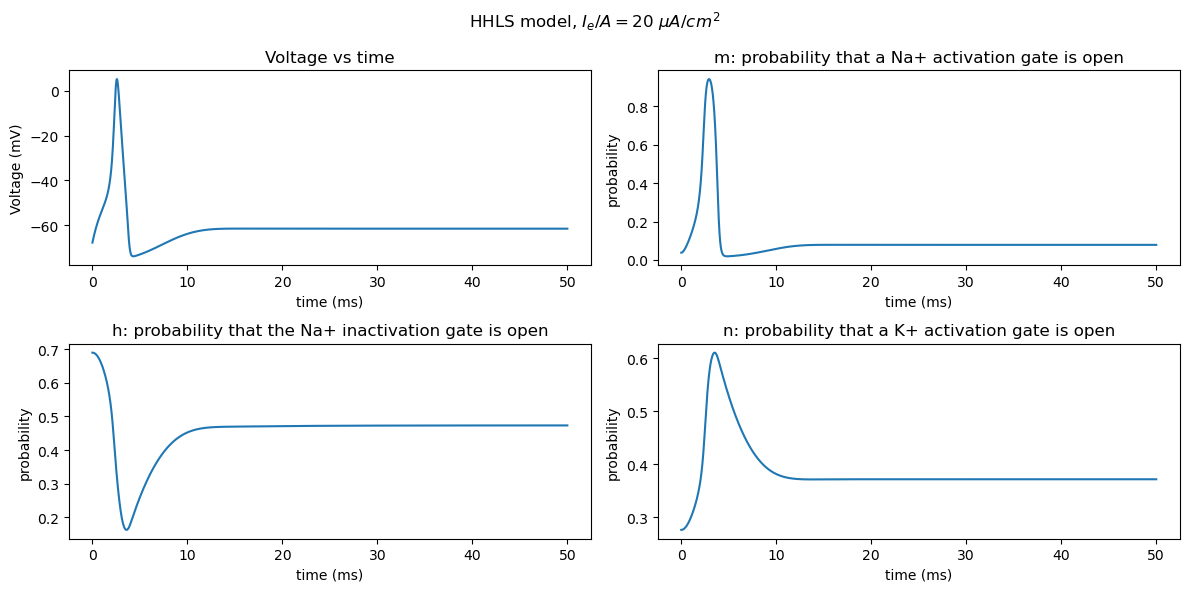

In [4]:
# ------------------------------------------------------------
# Simulate and Plot Response to I_e/A = 20 uA/cm^2 (= 200 nA/mm^2)
# ------------------------------------------------------------

I_ext = 20.0        # external current density I_e/A (uA/cm^2)
T = 50              # simulation interval (ms)
V_init = V0
m_init = m0
h_init = h0
n_init = n0

# Simulate the model.
t, V, m, h, n = simulate_hh(I_ext, T, dt, V_init, m_init, h_init, n_init)

# Plot V, m, h, and n versus time.
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
fig.suptitle(r"HHLS model, $I_e/A = 20\ \mu A/cm^2$")

axes[0,0].plot(t, V)
axes[0,0].set_title("Voltage vs time")
axes[0,0].set_xlabel("time (ms)")
axes[0,0].set_ylabel("Voltage (mV)")

axes[0,1].plot(t, m)
axes[0,1].set_title("m: probability that a Na+ activation gate is open")
axes[0,1].set_xlabel("time (ms)")
axes[0,1].set_ylabel("probability")

axes[1,0].plot(t, h)
axes[1,0].set_title("h: probability that the Na+ inactivation gate is open")
axes[1,0].set_xlabel("time (ms)")
axes[1,0].set_ylabel("probability")

axes[1,1].plot(t, n)
axes[1,1].set_title("n: probability that a K+ activation gate is open")
axes[1,1].set_xlabel("time (ms)")
axes[1,1].set_ylabel("probability")

plt.tight_layout()
plt.show()

# 2. Coincidence detector: replicating Hong, Ratté, Prescott & De Schutter (2012)

*Single Neuron Firing Properties Impact Correlation-Based Population Coding*, J Neurosci 32:1413–1428.

The paper uses the HHLS model above as its **coincidence detector (CD)**. Pairs of neurons receive Ornstein–Uhlenbeck (OU) noise currents

$$I_{1,2}(t) = \mu + \sigma\left(\sqrt{c}\,\zeta_c(t) + \sqrt{1-c}\,\zeta_{1,2}(t)\right),\qquad
d\zeta = -\frac{\zeta}{\tau}dt + \sqrt{2/\tau}\,\xi\sqrt{dt}\quad(\tau = 5\text{ ms}) \tag{1, 2}$$

A fraction $c$ of the fluctuations is shared. The question is how the output correlation $\rho$ (spike-count correlation, $T = 200$ ms) depends on $c$, $\mu$ and $\sigma^2$, and whether it can be predicted from single-neuron reverse correlation.

| Paper figure | CD panel reproduced below |
|---|---|
| **2A** | firing rate $\nu$ vs $\mu$ for several $\sigma^2$ (inset: $\nu$ vs $\sigma^2$) |
| **2B** | voltage response to a constant step (one spike) vs fluctuating input |
| **2C / 2D** | spike-triggered average (biphasic, narrow) and the CCG it predicts |
| **3A / 3B** | $\rho/c$ (measured vs first-order prediction, Eq. 29) vs $\mu$ and vs $\nu$, for high and low $\sigma^2$ ($c = 0.3$) |
| **4A / 4B** | $\rho$ vs $c$ for different $\mu$ plus a contour map (inset: Eq. 29), and a sample CCG at ≈12 Hz |
| **5A–F** | measured vs predicted covariance $C/c$ for: first order with $\tau = 5$ and $50$ ms, the ±2 ms peak deleted, the second-order correction (Eq. 31), $c = 0.2$, and $C$ vs $c$ |

Not reproduced: the integrator (Morris–Lecar) panels, Fig. 6 (phenomenological filter-and-threshold model) and Fig. 7 (experiments).

**Units.** With $A = 100\ \mu m^2$, 1 pA ≡ 1 µA/cm². The paper's $\mu$ (pA) and $\sigma^2$ (pA²) therefore plug directly into `I_ext`. (The paper prints $\beta_m = 4e^{-0.556(V+65)}$, which is a typo for 0.0556 = 1/18. We keep 0.0556.)

In [5]:
import os, pickle, time
from scipy.signal import lfilter

CACHE_DIR = "cd_cache"          # simulation results are pickled here; delete the folder to re-run
os.makedirs(CACHE_DIR, exist_ok=True)
SCALE = 1.0                     # multiplies every simulated duration (e.g. 0.25 for a quick, noisier look)

def cached(name, fn):
    path = os.path.join(CACHE_DIR, name + ".pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    t0 = time.time(); out = fn()
    print(f"{name}: simulated in {time.time() - t0:.0f} s")
    with open(path, "wb") as f:
        pickle.dump(out, f)
    return out

## 2.1 Fast batched simulator

The paper simulates 2–10 × 30 min per stimulus condition. The scalar `simulate_hh` loop above runs about 10⁵ steps/s, which is far too slow for that. The simulator below therefore:

* integrates **N neurons at once** (numpy arrays of shape `(N,)`) with the same HHLS equations and parameters;
* uses **exponential Euler**. Each gate is updated as $z \leftarrow z_\infty + (z - z_\infty)e^{-dt/\tau_z}$ and $V$ relaxes toward its instantaneous steady state. This is stable at $dt = 0.025$ ms, and spike times agree with the plain-Euler $dt = 0.01$ ms integrator (checked below). The rate functions are tabulated on a 0.01 mV grid;
* generates the OU noise at 5 kHz (as in the paper) with the exact AR(1) update $\zeta_{k+1} = a\zeta_k + \sqrt{1-a^2}\,\xi_k$, $a = e^{-\Delta/\tau}$;
* gives neurons with the same `group` index the same common noise $\zeta_c$. Every pair inside a group is a "pair" in the paper's sense;
* records spike times (upward crossing of 0 mV). On the fly it also accumulates, per stimulus condition, the spike-triggered average of the white noise $x = \sigma(\sqrt c\,\xi_c + \sqrt{1-c}\,\xi_i)$ (Eq. 8, 200 ms window) and of the injected fluctuation $I-\mu$, plus the spike-triggered correlation matrix $Q$ (Eq. 9, 30 ms window). These are accumulated separately for even and odd neurons, so that predictions can multiply two **independent** estimates and avoid noise bias.

The simulated duration is ~1–2 min per condition rather than 30 min (the `SCALE` knob above). Estimates are therefore noisier than in the paper.

In [6]:
# =====================================================================
# Lookup tables for the gating kinetics (exponential-Euler factors)
# =====================================================================
DT_STIM = 0.2          # stimulus sampling interval (ms) = 5 kHz, as in the paper

def make_gate_tables(dt, v_min=-150.0, v_max=150.0, dv=0.01):
    V = np.arange(v_min, v_max + dv, dv)
    # nudge exact singular points (V=-40, V=-55) by a hair
    V_safe = np.where(np.isclose(V, -40.0) | np.isclose(V, -55.0), V + 1e-6, V)
    rows = []
    for a, b in ((alpha_m, beta_m), (alpha_h, beta_h), (alpha_n, beta_n)):
        al, be = a(V_safe), b(V_safe)
        tau, zinf = 1.0/(al + be), al/(al + be)
        rows += [zinf, 1.0 - np.exp(-dt/tau)]
    return dict(table=np.array(rows), v_min=v_min, dv=dv, n=len(V))


def simulate_hhls_batch(mu, sigma, c, group, tau=5.0, T=10_000.0, dt=0.025,
                        seed=0, cond=None, sta_win=200.0, q_win=30.0,
                        record_v=None, chunk=1000.0, verbose=True):
    """Simulate N independent HHLS neurons driven by OU current (paper Eqs. 1-2).

    mu, sigma, c : arrays (N,) -- mean (pA), SD (pA), input correlation of each neuron
    group        : int array (N,) -- neurons with the same group share the common noise
    tau          : OU correlation time (ms)
    T            : simulated time (ms)
    dt           : integration step (ms), must divide DT_STIM
    cond         : int array (N,) -- condition label; STA/STCor are pooled per condition
    record_v     : list of neuron indices whose V and I traces are stored

    Returns dict with spike times (ms) per neuron, and per-condition STA/STCor sums.
    """
    rng = np.random.default_rng(seed)
    mu, sigma, c = (np.asarray(x, float) for x in (mu, sigma, c))
    group = np.asarray(group); N = len(mu)
    cond = np.zeros(N, int) if cond is None else np.asarray(cond)
    n_cond, n_grp = cond.max() + 1, group.max() + 1
    nsub = int(round(DT_STIM/dt)); assert abs(nsub*dt - DT_STIM) < 1e-9
    tab = make_gate_tables(dt); table, vmin, dv, nt = tab['table'], tab['v_min'], tab['dv'], tab['n']

    # OU (exact AR(1) discretisation) -- unit variance
    a = np.exp(-DT_STIM/tau); b = np.sqrt(1 - a*a)
    zc = rng.standard_normal(n_grp); zi = rng.standard_normal(N)   # start in stationary state
    sc, si = np.sqrt(c), np.sqrt(1 - c)

    # state, started at rest
    V = np.full(N, V0); m = np.full(N, m0); h = np.full(N, h0); n = np.full(N, n0)

    W, W2 = int(round(sta_win/DT_STIM)), int(round(q_win/DT_STIM))
    # accumulators split into two independent halves (even / odd neurons) -> unbiased products later
    half = np.arange(N) % 2
    sta_sum = np.zeros((2, n_cond, W)); staI_sum = np.zeros((2, n_cond, W)); q_sum = np.zeros((2, n_cond, W2, W2)); nspk_c = np.zeros((2, n_cond))
    x_tail = np.zeros((W - 1, N))                                    # white-noise history
    I_tail = np.zeros((W - 1, N))                                    # injected-fluctuation history
    spikes = [[] for _ in range(N)]
    rec = None
    if record_v is not None:
        record_v = np.asarray(record_v)
        nrec = int(round(T/dt))
        rec = dict(V=np.zeros((nrec, len(record_v)), np.float32),
                   I=np.zeros((nrec, len(record_v)), np.float32))

    n_chunks = int(np.ceil(T/chunk)); K = int(round(chunk/DT_STIM))
    step = 0; t0 = time.time()
    for ch in range(n_chunks):
        # ---- stimulus for this chunk (Eq. 1) ----
        xi_c = rng.standard_normal((K, n_grp)); xi_i = rng.standard_normal((K, N))
        zc_ch, _ = lfilter([b], [1, -a], xi_c, axis=0, zi=(a*zc)[None, :]); zc = zc_ch[-1]
        zi_ch, _ = lfilter([b], [1, -a], xi_i, axis=0, zi=(a*zi)[None, :]); zi = zi_ch[-1]
        I_ch = mu + sigma*(sc*zc_ch[:, group] + si*zi_ch)
        x_ch = sigma*(sc*xi_c[:, group] + si*xi_i)               # unfiltered (white) part, for STA
        del zc_ch, zi_ch, xi_i
        spk_k, spk_n = [], []
        # ---- integrate ----
        for k in range(K):
            I = I_ch[k]
            for _ in range(nsub):
                idx = ((V - vmin)/dv + 0.5).astype(np.intp)
                np.clip(idx, 0, nt - 1, out=idx)
                g = table[:, idx]
                m += g[1]*(g[0] - m); h += g[3]*(g[2] - h); n += g[5]*(g[4] - n)
                gna = gbar_Na*m*m*m*h; gk = gbar_K*(n*n)*(n*n)
                G = gna + gk + g_L
                Vinf = (gna*E_Na + gk*E_K + g_L*E_L + I)/G
                Vnew = Vinf + (V - Vinf)*np.exp(-dt*G/C_m)
                cross = (V < 0.0) & (Vnew >= 0.0)
                V = Vnew
                if cross.any():
                    for j in np.flatnonzero(cross):
                        spikes[j].append(step*dt)
                        spk_k.append(k); spk_n.append(j)
                if rec is not None:
                    rec['V'][step] = V[record_v]; rec['I'][step] = I[record_v]
                step += 1
        # ---- spike-triggered statistics for this chunk ----
        if spk_k:
            buf = np.concatenate([x_tail, x_ch], axis=0)        # (W-1+K, N)
            bufI = np.concatenate([I_tail, I_ch - mu], axis=0)
            kk = np.array(spk_k) + W - 1; nn = np.array(spk_n)
            ok = (kk - (W - 1)) + ch*K >= W - 1                  # skip spikes before a full window exists
            kk, nn = kk[ok], nn[ok]
            if len(kk):
                win = buf[kk[:, None] - np.arange(W)[None, :], nn[:, None]]   # (nspk, W), lag 0..W-1
                winI = bufI[kk[:, None] - np.arange(W)[None, :], nn[:, None]]
                cc, hh = cond[nn], half[nn]
                for hu in (0, 1):
                    for cu in np.unique(cc[hh == hu]):
                        sel = (cc == cu) & (hh == hu)
                        sta_sum[hu, cu] += win[sel].sum(0)
                        staI_sum[hu, cu] += winI[sel].sum(0)
                        w2 = win[sel, :W2]
                        q_sum[hu, cu] += w2.T @ w2
                        nspk_c[hu, cu] += sel.sum()
        x_tail = x_ch[-(W - 1):]; I_tail = (I_ch - mu)[-(W - 1):]
        if verbose:
            el = time.time() - t0
            print(f"\r  chunk {ch+1}/{n_chunks}  ({el:.0f} s elapsed, ~{el/(ch+1)*(n_chunks-ch-1):.0f} s left)",
                  end="", flush=True)
    if verbose: print()
    return dict(spikes=[np.array(s) for s in spikes], T=T, mu=mu, sigma=sigma, c=c, group=group,
                cond=cond, tau=tau, sta_sum=sta_sum, staI_sum=staI_sum, q_sum=q_sum, nspk_cond=nspk_c, rec=rec,
                rec_idx=record_v, dt=dt)


spikes in 1 s of constant input (5..400 pA): [0, 0, 1, 1, 1, 1, 1]  <- at most one onset spike
OU check: var = 0.997 (expect 1),  autocorr at lag tau = 0.364 (expect 0.368)


spike times, exp-Euler dt=0.025: [ 36.   99.7 127.9 145.6 287.9 319.7 340.8 462.6 487.  671.3 716.9 748.3
 781.  832.4]
spike times, Euler     dt=0.010: [ 36.   57.6  99.7 128.  145.6 287.9 319.7 340.9 462.7 487.  671.3 717.
 748.3 781.  832.4]


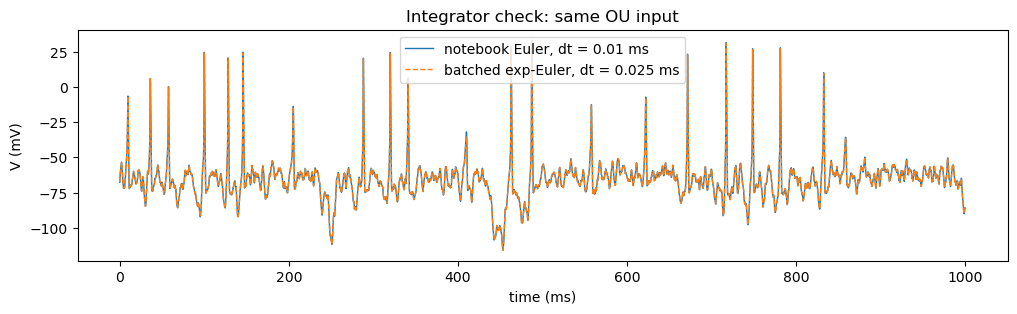

In [7]:
# ------------------------------------------------------------
# Checks: type-3 excitability, OU statistics, agreement with the notebook's Euler integrator
# ------------------------------------------------------------
r = simulate_hhls_batch(mu=[5, 10, 25, 50, 100, 200, 400], sigma=[0]*7, c=[0]*7, group=range(7),
                        T=1000, verbose=False)
print("spikes in 1 s of constant input (5..400 pA):", [len(s) for s in r['spikes']], " <- at most one onset spike")

rng = np.random.default_rng(0); a = np.exp(-DT_STIM/5.0)
z = lfilter([np.sqrt(1 - a*a)], [1, -a], rng.standard_normal(500_000))
lag = int(5.0/DT_STIM)
print(f"OU check: var = {z.var():.3f} (expect 1),  autocorr at lag tau = {np.corrcoef(z[:-lag], z[lag:])[0,1]:.3f} (expect {np.exp(-1):.3f})")

# Same noisy current through both integrators
r = simulate_hhls_batch([10.0], [np.sqrt(200)], [0.0], [0], T=1000, seed=7, record_v=[0], verbose=False)
nsub = int(round(DT_STIM/0.025))
I_samples = r['rec']['I'][::nsub, 0].astype(float)                 # one value per 0.2 ms
n_t = len(np.arange(0, 1000 + dt, dt))                             # length of simulate_hh's time vector
I_fine = np.repeat(I_samples, int(round(DT_STIM/dt)))              # hold for the notebook's dt = 0.01 ms
I_fine = np.r_[I_fine, np.full(max(0, n_t - len(I_fine)), I_fine[-1])][:n_t]
t_e, V_e, *_ = simulate_hh(I_fine, 1000, dt, V0, m0, h0, n0)
sp_e = t_e[1:][(V_e[:-1] < 0) & (V_e[1:] >= 0)]
print("spike times, exp-Euler dt=0.025:", np.round(r['spikes'][0], 1))
print("spike times, Euler     dt=0.010:", np.round(sp_e, 1))

t_b = np.arange(len(r['rec']['V']))*0.025
plt.figure(figsize=(12, 3))
plt.plot(t_e, V_e, lw=1, label="notebook Euler, dt = 0.01 ms")
plt.plot(t_b, r['rec']['V'][:, 0], '--', lw=1, label="batched exp-Euler, dt = 0.025 ms")
plt.xlabel("time (ms)"); plt.ylabel("V (mV)"); plt.legend(); plt.title("Integrator check: same OU input"); plt.show()

## 2.2 Correlation analysis and predictions

* **CCG** (Eq. 10): spike trains are binned at 1 ms. CC(τ) = CCF(τ) − CCF_shuffle(τ). The shuffle pairs a neuron with a neuron from a *different* group, which has independent common noise. The result is averaged over all pairs of a condition, in Hz².
* **Count covariance and correlation** (Eqs. 11–13): $C = \int CC(\tau)\,(T-|\tau|)\,d\tau$ with $T = 200$ ms, and $\rho = C/\sqrt{C_1C_2}$ using the shuffle-corrected autocorrelogram.
* **First-order prediction** (Eq. 29): $CCG_1(t) = c\,\frac{\nu_1\nu_2}{\sigma_1\sigma_2}\sum_j STA_1(j)\,STA_2(j+t)$, with the STA of the white noise $x$.
* **Second-order correction** (Eq. 31): $\delta CCG_2(t) = c^2\frac{\nu_1\nu_2}{2\sigma_1^2\sigma_2^2}\sum_{j,k}Q_1(j,k)\,Q_2(j+t,k+t)$, where $Q = \langle x x^T\rangle_{spike} - \sigma^2 I$ (= STA·STAᵀ + STC).
* Predicted $C$ and $\rho$ are obtained from the predicted CCG exactly as for the measured one. **Peak deletion** (Fig. 5C) zeroes $|\tau| \le 2$ ms in both before integrating. $R^2$ follows Eq. 15.

In [8]:
# =====================================================================
# Analysis: CCG (Eq. 10), spike-count covariance / correlation (Eqs. 11-13)
# =====================================================================
BIN = 1.0      # ms
T_WIN = 200.0  # spike-count window T (ms)
T_BURN = 500.0 # discard the onset transient (ms)

def _xcorr(a, b, maxlag, nfft):
    """sum_s a[..., s] b[..., s+tau] for tau=-maxlag..maxlag (last axis)."""
    r = np.fft.irfft(np.conj(np.fft.rfft(a, nfft)) * np.fft.rfft(b, nfft), nfft)
    return np.concatenate([r[..., nfft - maxlag:], r[..., :maxlag + 1]], axis=-1)

def binned(spk, T, t0=T_BURN):
    L = int((T - t0)//BIN)
    y = np.zeros(L)
    k = ((spk[spk >= t0] - t0)//BIN).astype(int)
    np.add.at(y, k[k < L], 1)
    return y

def condition_ccg(res, idx, maxlag=200):
    """Pair-averaged, shuffle-corrected CCG and ACG (Hz^2) for the neurons `idx` of one condition.
    Pairs = neurons in the same group (shared common noise); shuffle = neuron in group k x group k+1."""
    T = res['T']; groups = np.unique(res['group'][idx])
    Y = {g: np.array([binned(res['spikes'][i], T) for i in idx if res['group'][i] == g]) for g in groups}
    L = next(iter(Y.values())).shape[1]; nfft = int(2**np.ceil(np.log2(2*L)))
    lags = np.arange(-maxlag, maxlag + 1)
    norm = (L - np.abs(lags)) * (BIN*1e-3)**2           # -> Hz^2
    ccf, acf, shf = 0, 0, 0
    S = {g: Y[g].sum(0) for g in groups}
    for gi, g in enumerate(groups):
        M = len(Y[g])
        auto = _xcorr(Y[g], Y[g], maxlag, nfft)           # (M, lags)
        ccf = ccf + (_xcorr(S[g], S[g], maxlag, nfft) - auto.sum(0)) / (M*(M - 1))
        acf = acf + auto.mean(0)
        g2 = groups[(gi + 1) % len(groups)]
        shf = shf + _xcorr(S[g], S[g2], maxlag, nfft) / (M*len(Y[g2]))
    G = len(groups)
    ccf, acf, shf = ccf/G/norm, acf/G/norm, shf/G/norm
    rate = np.mean([y.sum() for g in groups for y in Y[g]]) / (L*BIN*1e-3)
    return dict(lags=lags*BIN, cc=ccf - shf, ac=acf - shf, ccf=ccf, shuffle=shf, rate=rate)

def count_cov(lags_ms, cc, T=T_WIN, delete_peak=None):
    """Eq. 13: C_T = int CC(tau) (T - |tau|) dtau over |tau| < T.  lags in ms, cc in Hz^2 -> spikes^2."""
    lags_ms = np.asarray(lags_ms); d = (lags_ms[1] - lags_ms[0])*1e-3
    w = np.clip(T - np.abs(lags_ms), 0, None)*1e-3
    if delete_peak is not None:
        w = np.where(np.abs(lags_ms) <= delete_peak, 0.0, w)
    return np.sum(cc*w)*d


# =====================================================================
# Reverse correlation (Eqs. 8-9) and CCG predictions (Eqs. 29, 31)
# =====================================================================
def sta_q(res, cu):
    """STA (pA; index j = j*0.2 ms before the spike) and STCor Q for condition cu, for each half."""
    n = res['nspk_cond'][:, cu]
    sig2 = res['sigma'][res['cond'] == cu][0]**2
    sta = res['sta_sum'][:, cu] / n[:, None]
    Q = res['q_sum'][:, cu] / n[:, None, None] - sig2*np.eye(res['q_sum'].shape[-1])[None]   # E_spk[x x^T] - Cov_prior
    return sta, Q, n

def predicted_ccg(res, cu, rate, order=2):
    """First-order (Eq. 29) and second-order (Eq. 31) predicted CCGs (Hz^2) for a pair in condition cu.
    STA/Q of 'neuron 1' and 'neuron 2' come from independent halves -> no estimation-noise bias."""
    sta, Q, _ = sta_q(res, cu)
    m = res['cond'] == cu
    sig, c = res['sigma'][m][0], res['c'][m][0]
    W = sta.shape[1]
    # sum_j STA1[j] STA2[j+s]  (s>0: neuron 2 later)
    full = 0.5*(np.correlate(sta[1], sta[0], 'full') + np.correlate(sta[0], sta[1], 'full'))
    s = np.arange(-(W - 1), W)
    ccg1 = c*rate*rate/sig**2 * full
    out = dict(lags=s*DT_STIM, ccg1=ccg1)
    if order >= 2:
        W2 = Q.shape[1]; s2 = np.arange(-(W2 - 1), W2); d2 = np.zeros(len(s2))
        for k, sh in enumerate(s2):
            a, b = (Q[0], Q[1]) if sh >= 0 else (Q[1], Q[0])
            sh = abs(sh)
            v = np.sum(a[:W2 - sh, :W2 - sh] * b[sh:, sh:])
            a, b = b, a
            v2 = np.sum(a[:W2 - sh, :W2 - sh] * b[sh:, sh:])
            d2[k] = 0.5*(v + v2)
        dccg2 = c*c*rate*rate/(2*sig**4) * d2
        ccg2 = ccg1.copy(); off = W - W2
        ccg2[off:off + len(s2)] += dccg2
        out.update(ccg2=ccg2)
    return out

def to_bins(lags_ms, y, bin_ms=BIN, maxlag=200):
    """Average a finely-sampled CCG into BIN-wide bins centred on integer lags (for overlays)."""
    centers = np.arange(-maxlag, maxlag + 1)*bin_ms
    out = np.array([y[np.abs(lags_ms - t) < bin_ms/2 - 1e-9].mean() if np.any(np.abs(lags_ms - t) < bin_ms/2) else 0
                    for t in centers])
    return centers, out

def r2(meas, pred):
    meas, pred = np.asarray(meas), np.asarray(pred)
    return 1 - np.sum((meas - pred)**2)/np.sum((meas - meas.mean())**2)


def analyse_conditions(res, conds=None, maxlag=200, order=2):
    """Everything per condition: rate, measured CC/rho, predicted (1st, 2nd order) C/rho."""
    out = []
    conds = np.unique(res['cond']) if conds is None else conds
    for cu in conds:
        idx = np.flatnonzero(res['cond'] == cu)
        m = ccg_m = condition_ccg(res, idx, maxlag)
        Ca = count_cov(m['lags'], m['ac'])
        C = count_cov(m['lags'], m['cc'])
        r = dict(cond=cu, mu=res['mu'][idx[0]], sigma=res['sigma'][idx[0]], c=res['c'][idx[0]],
                 rate=m['rate'], C=C, Ca=Ca, rho=C/Ca, lags=m['lags'], cc=m['cc'],
                 C_del=count_cov(m['lags'], m['cc'], delete_peak=2.0))
        if res['nspk_cond'][:, cu].min() > 50 and m['rate'] > 0:
            p = predicted_ccg(res, cu, m['rate'], order)
            r.update(plags=p['lags'], pccg1=p['ccg1'], C1=count_cov(p['lags'], p['ccg1']),
                     C1_del=count_cov(p['lags'], p['ccg1'], delete_peak=2.0))
            r['rho1'] = r['C1']/Ca
            if order >= 2:
                r.update(pccg2=p['ccg2'], C2=count_cov(p['lags'], p['ccg2']))
                r['rho2'] = r['C2']/Ca
        out.append(r)
    return out


In [9]:
def make_population(conditions, n_groups=4, n_per_group=10):
    '''conditions: list of (mu [pA], sigma^2 [pA^2], c) or (mu, sigma^2, c, n_groups, n_per_group).
    Each condition gets n_groups independent common-noise groups of n_per_group neurons.'''
    out = {k: [] for k in ("mu", "sigma", "c", "group", "cond")}
    g = 0
    for ci, cd in enumerate(conditions):
        m_, s2, c_ = cd[:3]
        ng, npg = (cd[3], cd[4]) if len(cd) == 5 else (n_groups, n_per_group)
        for _ in range(ng):
            for _ in range(npg):
                for k, v in zip(out, (m_, np.sqrt(s2), c_, g, ci)):
                    out[k].append(v)
            g += 1
    return {k: np.array(v) for k, v in out.items()}

def run_population(conditions, T, tau=5.0, seed=0, **kw):
    pop = make_population(conditions, **kw)
    print(f"simulating {len(pop['mu'])} neurons x {T/1000:.0f} s (tau = {tau} ms)")
    return simulate_hhls_batch(pop['mu'], pop['sigma'], pop['c'], pop['group'], tau=tau, T=T,
                               seed=seed, cond=pop['cond'])

### Matching the paper's operating regimes

Run with the printed HHLS parameters, this model reproduces the paper's *qualitative* rate surface (Fig. 2A below): no repetitive firing to constant input, a rise-then-fall of $\nu(\mu)$, and strong $\sigma$-dependence. The absolute numbers differ, though.
* $\nu(\mu)$ peaks near $\mu \approx 0$ pA here, versus ≈ 120 pA in the paper.
* The model fires at much smaller $\sigma^2$. Peak rates of ~30 Hz need $\sigma^2 \approx 800$ pA² rather than 2500 pA².

Changing the temperature factor or using the literal printed $\beta_m$ constant (0.556) does not remove this offset. The paper's NEURON implementation presumably differed in some unreported detail.

So instead of the paper's literal $(\mu, \sigma^2)$ values, each figure uses values that put the model in the **same regime** (same side of the $\nu(\mu)$ peak and similar firing-rate range):

| Figure | Paper ($\mu$ in pA; $\sigma^2$ in pA²) | Used here |
|---|---|---|
| 2A | $\mu$ −150…300, $\sigma^2$ 0…2500 | $\mu$ −120…150, $\sigma^2$ 0…800 |
| 2B, 2C | $\mu$ = 200, $\sigma^2$ = 1360 (≈15–20 Hz, just past the peak) | $\mu$ = 10, $\sigma^2$ = 200 (≈16 Hz) |
| 3 high / low $\sigma^2$ | 2000 / 520, rising side of $\nu(\mu)$ | 800 / 50, $\mu \le 0$ |
| 4 | $\sigma^2$ = 1000, $\mu$ −50…200 | $\sigma^2$ = 200, $\mu$ −30…20 |
| 5 ($\tau$ = 5 ms) | $\mu$ −150…200, $\sigma^2$ 1000…2500 | $\mu$ −60…30, $\sigma^2$ 100…800 |
| 5 ($\tau$ = 50 ms) | $\mu$ −100…100, $\sigma^2$ 400…4400 | $\mu$ −60…60, $\sigma^2$ 400…3200 |

## 2.3 Figure 2 (right column): the HHLS neuron is a coincidence detector

In [10]:
FIG2_S2 = [0, 50, 100, 200, 400, 800]          # sigma^2 (pA^2)
FIG2_MU = np.arange(-120, 151, 10)              # mu (pA)
STA_MU, STA_S2 = 10, 200                        # condition used for the STA (paper: 200 pA, 1360 pA^2)
INSET_MU = (-40, 0)                             # gray / black arrows in the inset

def _fig2():
    conds = [(m, s2, 0.0, 1, 4) for s2 in FIG2_S2 for m in FIG2_MU]   # 4 neurons per point
    conds.append((STA_MU, STA_S2, 0.0, 1, 200))                       # 200 neurons for the STA
    return run_population(conds, T=30_000*SCALE, seed=2)

res2 = cached("fig2", _fig2)
n_mu = len(FIG2_MU)
rate2 = np.array([np.mean([np.sum(res2['spikes'][i] > T_BURN) for i in np.flatnonzero(res2['cond'] == ci)])
                  for ci in range(res2['cond'].max() + 1)]) / ((res2['T'] - T_BURN)/1000)
rate_grid = rate2[:-1].reshape(len(FIG2_S2), n_mu)

simulating 872 neurons x 30 s (tau = 5.0 ms)



  chunk 1/30  (1 s elapsed, ~35 s left)


  chunk 2/30  (2 s elapsed, ~33 s left)


  chunk 3/30  (4 s elapsed, ~32 s left)


  chunk 4/30  (5 s elapsed, ~30 s left)


  chunk 5/30  (6 s elapsed, ~29 s left)

... (22 outputs left out)


  chunk 28/30  (33 s elapsed, ~2 s left)


  chunk 29/30  (34 s elapsed, ~1 s left)


  chunk 30/30  (36 s elapsed, ~0 s left)


fig2: simulated in 36 s


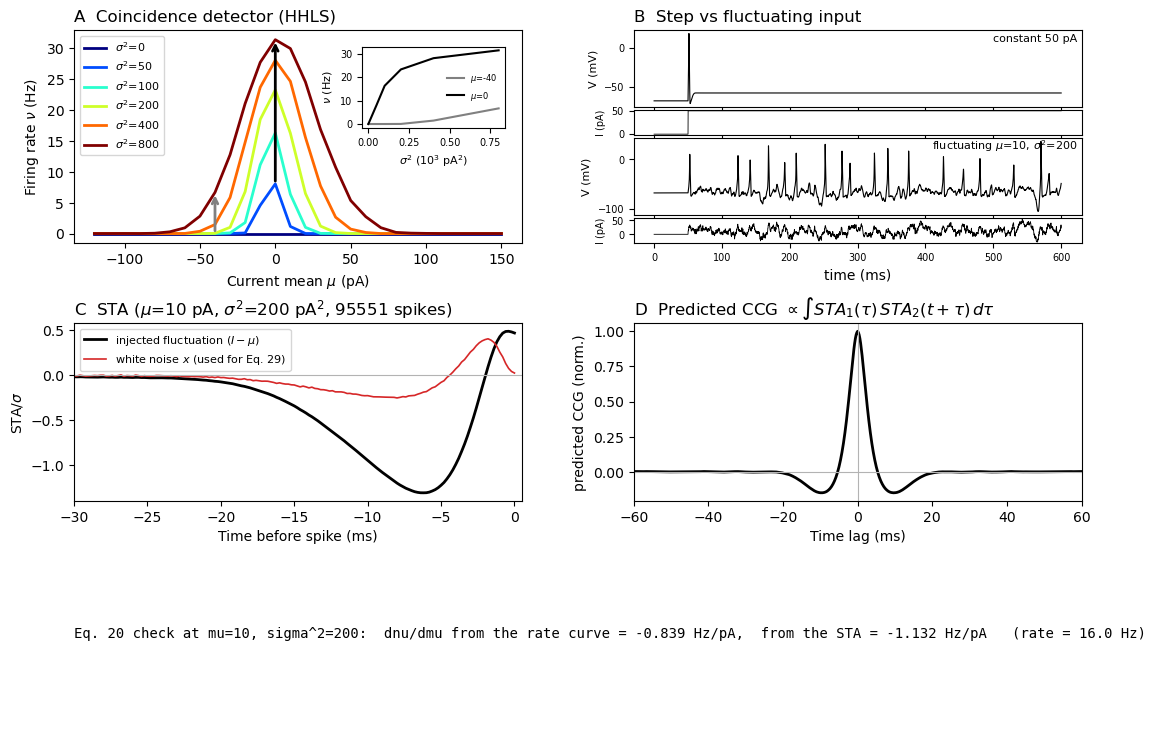

In [11]:
from matplotlib import cm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

fig = plt.figure(figsize=(13, 9))
gs = fig.add_gridspec(3, 2, height_ratios=[1.2, 1, 0.8], hspace=0.45, wspace=0.25)

# ---- A: nu vs mu for each sigma^2 ----
axA = fig.add_subplot(gs[0, 0])
cols = cm.jet(np.linspace(0, 1, len(FIG2_S2)))
for k, s2 in enumerate(FIG2_S2):
    axA.plot(FIG2_MU, rate_grid[k], color=cols[k], lw=2, label=fr"$\sigma^2$={s2}")
for m_, col in zip(INSET_MU, ("gray", "k")):
    j = np.argmin(np.abs(FIG2_MU - m_))
    axA.annotate("", xy=(m_, rate_grid[-1, j]), xytext=(m_, rate_grid[1, j]),
                 arrowprops=dict(arrowstyle="->", color=col, lw=2))
axA.set_xlabel(r"Current mean $\mu$ (pA)"); axA.set_ylabel(r"Firing rate $\nu$ (Hz)")
axA.set_title("A  Coincidence detector (HHLS)", loc="left"); axA.legend(fontsize=8, loc="upper left")
ins = inset_axes(axA, width="32%", height="38%", loc="upper right", borderpad=1.2)
for m_, col in zip(INSET_MU, ("gray", "k")):
    j = np.argmin(np.abs(FIG2_MU - m_))
    ins.plot(np.array(FIG2_S2)/1e3, rate_grid[:, j], color=col, label=fr"$\mu$={m_}")
ins.set_xlabel(r"$\sigma^2$ ($10^3$ pA$^2$)", fontsize=8); ins.set_ylabel(r"$\nu$ (Hz)", fontsize=8)
ins.tick_params(labelsize=7); ins.legend(fontsize=6, frameon=False)

# ---- B: constant vs fluctuating input (notebook's own Euler integrator, onset at 50 ms) ----
T_tr, t_on = 600.0, 50.0
nb_steps = len(np.arange(0, T_tr + dt, dt))
I_step = np.where(np.arange(nb_steps)*dt >= t_on, STA_MU + 40.0, 0.0)
a_ = np.exp(-DT_STIM/5.0); rng = np.random.default_rng(11)
zeta = lfilter([np.sqrt(1 - a_**2)], [1, -a_], rng.standard_normal(int(T_tr/DT_STIM) + 2))
I_fl = np.repeat(STA_MU + np.sqrt(STA_S2)*zeta, int(round(DT_STIM/dt)))[:nb_steps]   # zeta is long enough
I_fl = np.where(np.arange(nb_steps)*dt >= t_on, I_fl, 0.0)
gsB = gs[0, 1].subgridspec(4, 1, height_ratios=[3, 1, 3, 1], hspace=0.05)
for row, (I_tr, lab) in enumerate(((I_step, f"constant {STA_MU + 40:.0f} pA"),
                                    (I_fl, fr"fluctuating $\mu$={STA_MU}, $\sigma^2$={STA_S2}"))):
    t_, V_, *_ = simulate_hh(I_tr, T_tr, dt, V0, m0, h0, n0)
    axv = fig.add_subplot(gsB[2*row]); axi = fig.add_subplot(gsB[2*row + 1], sharex=axv)
    axv.plot(t_, V_, 'k', lw=0.8); axv.set_ylabel("V (mV)", fontsize=8); axv.text(0.99, 0.85, lab, ha="right",
            transform=axv.transAxes, fontsize=8)
    axi.plot(t_, I_tr, 'k', lw=0.6); axi.set_ylabel("I (pA)", fontsize=7)
    for ax_ in (axv, axi): ax_.tick_params(labelsize=7)
    if row == 0: axv.set_title("B  Step vs fluctuating input", loc="left")
axi.set_xlabel("time (ms)")

# ---- C: STA ----
cu = res2['cond'].max()
staW = res2['sta_sum'][:, cu].sum(0) / res2['nspk_cond'][:, cu].sum()     # white-noise STA (used in Eq. 29)
staI = res2['staI_sum'][:, cu].sum(0) / res2['nspk_cond'][:, cu].sum()    # STA of injected fluctuation I - mu
lagC = -np.arange(staW.size)*DT_STIM
sig = np.sqrt(STA_S2)
axC = fig.add_subplot(gs[1, 0])
axC.plot(lagC, staI/sig, 'k', lw=2, label=r"injected fluctuation $(I-\mu)$")
axC.plot(lagC, staW/sig, color="tab:red", lw=1.2, label=r"white noise $x$ (used for Eq. 29)")
axC.axhline(0, color="0.7", lw=0.8); axC.set_xlim(-30, 0.5)
axC.set_xlabel("Time before spike (ms)"); axC.set_ylabel(r"STA/$\sigma$")
axC.set_title(fr"C  STA ($\mu$={STA_MU} pA, $\sigma^2$={STA_S2} pA$^2$, {int(res2['nspk_cond'][:, cu].sum())} spikes)",
              loc="left")
axC.legend(fontsize=8)

# ---- D: STA (x) STA -> predicted CCG shape ----
axD = fig.add_subplot(gs[1, 1])
full = np.correlate(staW, staW, 'full'); lagD = np.arange(-(staW.size - 1), staW.size)*DT_STIM
axD.plot(lagD, full/full.max(), 'k', lw=2)
axD.axhline(0, color="0.7", lw=0.8); axD.axvline(0, color="0.7", lw=0.8); axD.set_xlim(-60, 60)
axD.set_xlabel("Time lag (ms)"); axD.set_ylabel("predicted CCG (norm.)")
axD.set_title(r"D  Predicted CCG $\propto \int STA_1(\tau)\,STA_2(t+\tau)\,d\tau$", loc="left")

# ---- Eq. 20 sanity check:  d nu / d mu  =  (nu / sigma^2) * sum_j STA_x[j] * (1 - a)/sqrt(1 - a^2) ----
k_s2 = FIG2_S2.index(STA_S2); j = np.argmin(np.abs(FIG2_MU - STA_MU))
dnu_dmu_fd = (rate_grid[k_s2, j + 1] - rate_grid[k_s2, j - 1]) / (FIG2_MU[j + 1] - FIG2_MU[j - 1])
nu_sta = rate2[-1]; a5 = np.exp(-DT_STIM/5.0)
dnu_dmu_sta = nu_sta / STA_S2 * staW.sum() * (1 - a5)/np.sqrt(1 - a5**2)
axS = fig.add_subplot(gs[2, :]); axS.axis("off")
axS.text(0, 0.6, f"Eq. 20 check at mu={STA_MU}, sigma^2={STA_S2}:  dnu/dmu from the rate curve = {dnu_dmu_fd:.3f} Hz/pA,"
         f"  from the STA = {dnu_dmu_sta:.3f} Hz/pA   (rate = {nu_sta:.1f} Hz)", fontsize=10, family="monospace")
plt.show()

**What to look for (paper Fig. 2, right):**
* Constant input evokes at most one onset spike (type-3 excitability). Fluctuating input evokes spikes on fast upswings.
* $\nu$ depends strongly on $\sigma$, and $\nu(\mu)$ is non-monotonic.
* The STA has a narrow positive lobe a few ms before the spike, preceded by a negative lobe (high-pass, "biphasic"). Its autocorrelation, which is the predicted CCG shape, is narrow with negative side lobes.

## 2.4 Figure 3 (bottom row): output correlation vs mean input, high vs low variance ($c = 0.3$)

In [12]:
FIG3 = {"High variance": (800, np.arange(-90, 11, 10)),
        "Low variance":  (50,  np.arange(-24, 1, 3))}
C_FIG3 = 0.3

def _fig3():
    conds = [(m, s2, C_FIG3) for s2, mus in FIG3.values() for m in mus]
    return run_population(conds, T=120_000*SCALE, seed=3)

res3 = cached("fig3", _fig3)
A3 = analyse_conditions(res3, order=1)
ofs = np.cumsum([0] + [len(m) for _, m in FIG3.values()])

simulating 800 neurons x 120 s (tau = 5.0 ms)



  chunk 1/120  (1 s elapsed, ~131 s left)


  chunk 2/120  (2 s elapsed, ~130 s left)


  chunk 3/120  (3 s elapsed, ~130 s left)


  chunk 4/120  (4 s elapsed, ~129 s left)


  chunk 5/120  (6 s elapsed, ~128 s left)

... (112 outputs left out)


  chunk 118/120  (133 s elapsed, ~2 s left)


  chunk 119/120  (134 s elapsed, ~1 s left)


  chunk 120/120  (135 s elapsed, ~0 s left)


fig3: simulated in 135 s


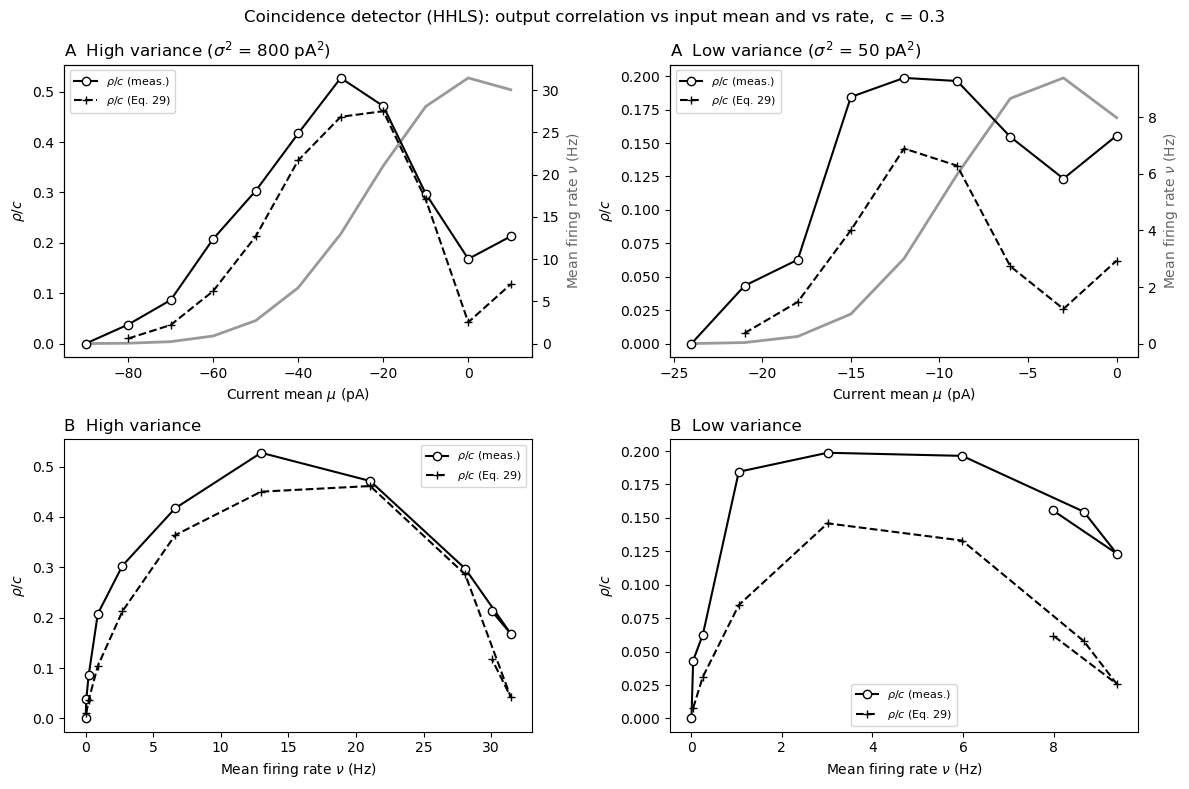

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, (name, (s2, mus)) in enumerate(FIG3.items()):
    A = A3[ofs[col]:ofs[col + 1]]
    nu = np.array([a['rate'] for a in A]); rc = np.array([a['rho'] for a in A])/C_FIG3
    rp = np.array([a.get('rho1', np.nan) for a in A])/C_FIG3
    ax = axes[0, col]; ax2 = ax.twinx()
    ax2.plot(mus, nu, color="0.6", lw=2); ax2.set_ylabel(r"Mean firing rate $\nu$ (Hz)", color="0.4")
    ax.plot(mus, rc, 'ko-', mfc="w", label=r"$\rho/c$ (meas.)")
    ax.plot(mus, rp, 'k+--', label=r"$\rho/c$ (Eq. 29)")
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.set_xlabel(r"Current mean $\mu$ (pA)"); ax.set_ylabel(r"$\rho/c$")
    ax.set_title(fr"A  {name} ($\sigma^2$ = {s2} pA$^2$)", loc="left"); ax.legend(loc="upper left", fontsize=8)
    ax = axes[1, col]
    ax.plot(nu, rc, 'ko-', mfc="w", label=r"$\rho/c$ (meas.)"); ax.plot(nu, rp, 'k+--', label=r"$\rho/c$ (Eq. 29)")
    ax.set_xlabel(r"Mean firing rate $\nu$ (Hz)"); ax.set_ylabel(r"$\rho/c$")
    ax.set_title(f"B  {name}", loc="left"); ax.legend(fontsize=8)
fig.suptitle("Coincidence detector (HHLS): output correlation vs input mean and vs rate,  c = 0.3")
plt.tight_layout(); plt.show()

**Paper's result:** for the coincidence detector, $\rho/c$ does not simply follow the rate. At high variance it peaks and then *decreases* while $\nu$ keeps rising. At low variance it stays nearly flat across rates. The first-order (rate-comodulation) prediction, Eq. 29, captures only part of the measured correlation, especially when $\partial\nu/\partial\mu$ is small.

## 2.5 Figure 4: correlation-based coding by the coincidence detector

In [14]:
FIG4_S2 = 200
FIG4_MU = np.array([-30, -20, -15, -10, 0, 10, 20])
FIG4_C = np.array([0.1, 0.2, 0.3, 0.4, 0.5])

def _fig4():
    conds = [(m, FIG4_S2, c_) for m in FIG4_MU for c_ in FIG4_C]
    return run_population(conds, T=60_000*SCALE, seed=4)

res4 = cached("fig4", _fig4)
A4 = analyse_conditions(res4, order=2)
grid = lambda key: np.array([a.get(key, np.nan) for a in A4]).reshape(len(FIG4_MU), len(FIG4_C))
rho4, rho4_1, rate4 = grid('rho'), grid('rho1'), grid('rate')

simulating 1400 neurons x 60 s (tau = 5.0 ms)



  chunk 1/60  (2 s elapsed, ~96 s left)


  chunk 2/60  (3 s elapsed, ~96 s left)


  chunk 3/60  (5 s elapsed, ~95 s left)


  chunk 4/60  (7 s elapsed, ~93 s left)


  chunk 5/60  (8 s elapsed, ~91 s left)

... (52 outputs left out)


  chunk 58/60  (95 s elapsed, ~3 s left)


  chunk 59/60  (97 s elapsed, ~2 s left)


  chunk 60/60  (98 s elapsed, ~0 s left)


fig4: simulated in 98 s


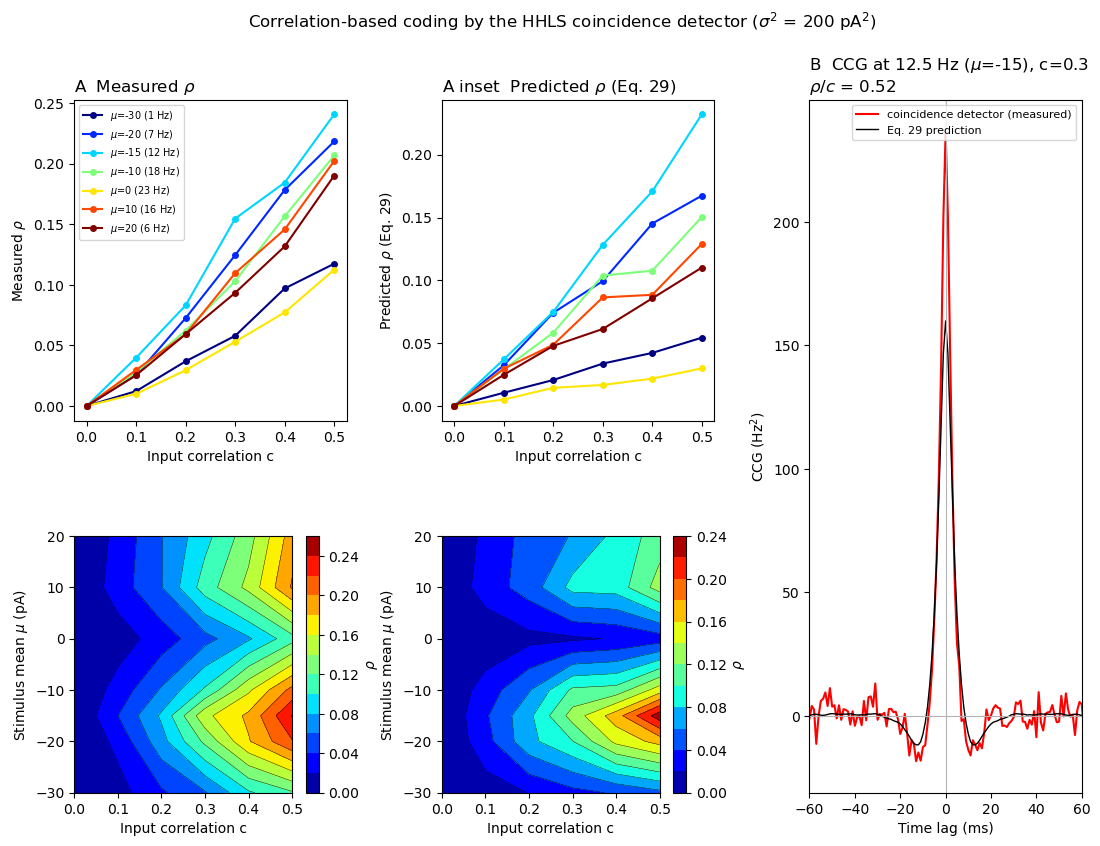

In [15]:
fig = plt.figure(figsize=(13, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 0.8], hspace=0.4, wspace=0.35)
cols = cm.jet(np.linspace(0, 1, len(FIG4_MU)))
c_full = np.r_[0, FIG4_C]
for k, (rho_, ttl) in enumerate(((rho4, r"Measured $\rho$"), (rho4_1, r"Predicted $\rho$ (Eq. 29)"))):
    ax = fig.add_subplot(gs[0, k])
    for i, m_ in enumerate(FIG4_MU):
        ax.plot(c_full, np.r_[0, rho_[i]], 'o-', color=cols[i], ms=4, label=fr"$\mu$={m_} ({rate4[i].mean():.0f} Hz)")
    ax.set_xlabel("Input correlation c"); ax.set_ylabel(ttl)
    ax.set_title(("A  " if k == 0 else "A inset  ") + ttl, loc="left")
    if k == 0: ax.legend(fontsize=7)
    ax = fig.add_subplot(gs[1, k])
    cs = ax.contourf(c_full, FIG4_MU, np.c_[np.zeros(len(FIG4_MU)), rho_], levels=12, cmap="jet")
    ax.contour(c_full, FIG4_MU, np.c_[np.zeros(len(FIG4_MU)), rho_], levels=12, colors="k", linewidths=0.3)
    plt.colorbar(cs, ax=ax, label=r"$\rho$"); ax.set_xlabel("Input correlation c"); ax.set_ylabel(r"Stimulus mean $\mu$ (pA)")

# ---- B: CCG of the condition closest to 12 Hz at c = 0.3 ----
ic = list(FIG4_C).index(0.3); im = np.argmin(np.abs(rate4[:, ic] - 12))
aB = A4[im*len(FIG4_C) + ic]
ax = fig.add_subplot(gs[:, 2])
ax.plot(aB['lags'], aB['cc'], 'r', lw=1.5, label="coincidence detector (measured)")
cB, pB = to_bins(aB['plags'], aB['pccg1'])
ax.plot(cB, pB, 'k', lw=1, label="Eq. 29 prediction")
ax.axhline(0, color="0.7", lw=0.8); ax.axvline(0, color="0.7", lw=0.8); ax.set_xlim(-60, 60)
ax.set_xlabel("Time lag (ms)"); ax.set_ylabel(r"CCG (Hz$^2$)")
ax.set_title(fr"B  CCG at {aB['rate']:.1f} Hz ($\mu$={aB['mu']:.0f}), c=0.3" + "\n" + fr"$\rho/c$ = {aB['rho']/0.3:.2f}", loc="left")
ax.legend(fontsize=8)
fig.suptitle(fr"Correlation-based coding by the HHLS coincidence detector ($\sigma^2$ = {FIG4_S2} pA$^2$)")
plt.show()

**Paper's result:** the $\rho$–$c$ curves for different $\mu$ cluster tightly for the coincidence detector. The contour lines are nearly vertical, so $c$ can be decoded from $\rho$ without knowing $\mu$. The first-order prediction (inset) misses most of $\rho$ and fans out with $\mu$. The CD CCG is narrow and biphasic.

## 2.6 Figure 5: why the first-order prediction fails, and the second-order fix

In [16]:
FIG5_MU5, FIG5_S2_5 = np.arange(-60, 31, 15), [100, 200, 400, 800]          # tau = 5 ms
FIG5_MU50, FIG5_S2_50 = np.arange(-60, 61, 20), [400, 800, 1600, 3200]       # tau = 50 ms
MIN_RATE = 1.0                                                              # drop near-silent conditions

def _fig5_tau5():
    conds = [(m, s2, c_) for c_ in (0.5, 0.2) for s2 in FIG5_S2_5 for m in FIG5_MU5]
    return run_population(conds, T=60_000*SCALE, tau=5.0, seed=5)

def _fig5_tau50():
    conds = [(m, s2, 0.5) for s2 in FIG5_S2_50 for m in FIG5_MU50]
    return run_population(conds, T=60_000*SCALE, tau=50.0, seed=6)

res5 = cached("fig5_tau5", _fig5_tau5)
res50 = cached("fig5_tau50", _fig5_tau50)
A5 = [a for a in analyse_conditions(res5, order=2) if a['rate'] >= MIN_RATE and 'C1' in a]
A50 = [a for a in analyse_conditions(res50, order=1) if a['rate'] >= MIN_RATE and 'C1' in a]
A5_c5 = [a for a in A5 if a['c'] == 0.5]; A5_c2 = [a for a in A5 if a['c'] == 0.2]
print(f"conditions kept: tau=5/c=0.5: {len(A5_c5)},  tau=5/c=0.2: {len(A5_c2)},  tau=50/c=0.5: {len(A50)}")

simulating 2240 neurons x 60 s (tau = 5.0 ms)



  chunk 1/60  (2 s elapsed, ~137 s left)


  chunk 2/60  (5 s elapsed, ~137 s left)


  chunk 3/60  (7 s elapsed, ~135 s left)


  chunk 4/60  (9 s elapsed, ~132 s left)


  chunk 5/60  (12 s elapsed, ~130 s left)

... (115 outputs left out)


  chunk 60/60  (77 s elapsed, ~0 s left)


fig5_tau50: simulated in 77 s


/var/folders/d9/20nm_19d0zdcl_z32tbyg3gm0000gn/T/ipykernel_92983/4055715377.py:111: RuntimeWarning: invalid value encountered in scalar divide
  rate=m['rate'], C=C, Ca=Ca, rho=C/Ca, lags=m['lags'], cc=m['cc'],


conditions kept: tau=5/c=0.5: 19,  tau=5/c=0.2: 19,  tau=50/c=0.5: 23


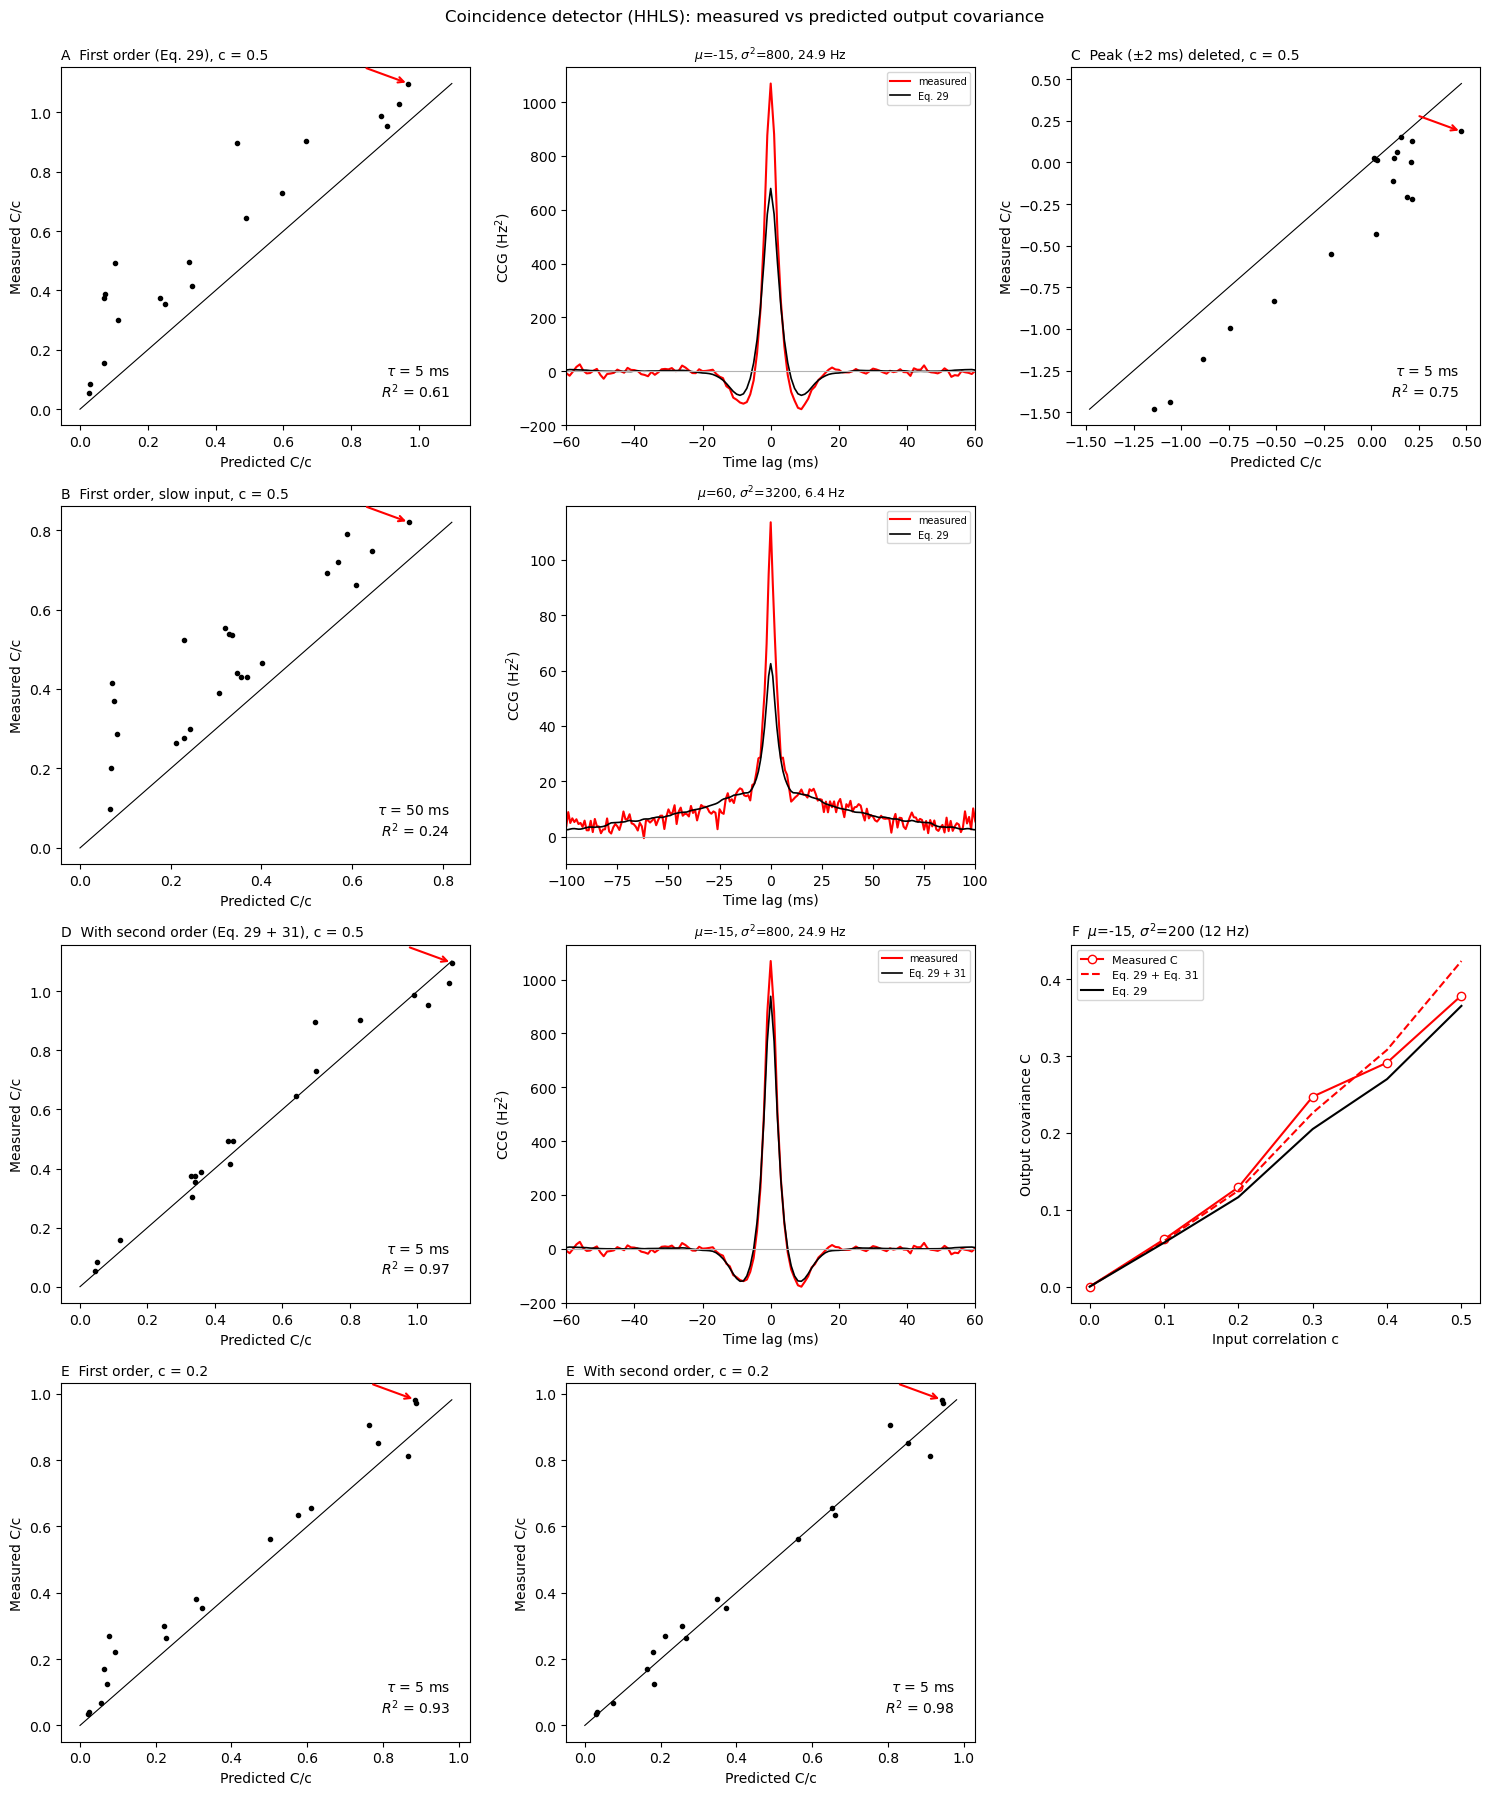

In [17]:
def scatter(ax, A, kx, ky, title, tau):
    x = np.array([a[kx] for a in A])/np.array([a['c'] for a in A])
    y = np.array([a[ky] for a in A])/np.array([a['c'] for a in A])
    ax.plot(x, y, 'k.', ms=6)
    lo, hi = min(x.min(), y.min(), 0), max(x.max(), y.max())
    ax.plot([lo, hi], [lo, hi], 'k-', lw=0.8)
    best = A[int(np.argmax(y))]                       # point used for the sample CCG
    ax.annotate("", xy=(best[kx]/best['c'], best[ky]/best['c']),
                xytext=(best[kx]/best['c'] - 0.12*(hi - lo), best[ky]/best['c'] + 0.05*(hi - lo)),
                arrowprops=dict(arrowstyle="->", color="r", lw=1.5))
    ax.text(0.95, 0.08, fr"$\tau$ = {tau} ms" + "\n" + fr"$R^2$ = {r2(y, x):.2f}", transform=ax.transAxes, ha="right")
    ax.set_xlabel("Predicted C/c"); ax.set_ylabel("Measured C/c"); ax.set_title(title, loc="left", fontsize=10)
    return best

def ccg_panel(ax, a, key, label, maxlag=60):
    ax.plot(a['lags'], a['cc'], 'r', lw=1.5, label="measured")
    cB, pB = to_bins(a['plags'], a[key])
    ax.plot(cB, pB, 'k', lw=1.2, label=label)
    ax.axhline(0, color="0.7", lw=0.8); ax.set_xlim(-maxlag, maxlag)
    ax.set_xlabel("Time lag (ms)"); ax.set_ylabel(r"CCG (Hz$^2$)"); ax.legend(fontsize=7)
    ax.set_title(fr"$\mu$={a['mu']:.0f}, $\sigma^2$={a['sigma']**2:.0f}, {a['rate']:.1f} Hz", fontsize=9)

fig, axes = plt.subplots(4, 3, figsize=(15, 18))
b = scatter(axes[0, 0], A5_c5, 'C1', 'C', "A  First order (Eq. 29), c = 0.5", 5);       ccg_panel(axes[0, 1], b, 'pccg1', "Eq. 29")
b = scatter(axes[1, 0], A50, 'C1', 'C', "B  First order, slow input, c = 0.5", 50);     ccg_panel(axes[1, 1], b, 'pccg1', "Eq. 29", 100)
scatter(axes[0, 2], A5_c5, 'C1_del', 'C_del', "C  Peak (±2 ms) deleted, c = 0.5", 5)
b = scatter(axes[2, 0], A5_c5, 'C2', 'C', "D  With second order (Eq. 29 + 31), c = 0.5", 5); ccg_panel(axes[2, 1], b, 'pccg2', "Eq. 29 + 31")
scatter(axes[3, 0], A5_c2, 'C1', 'C', "E  First order, c = 0.2", 5)
scatter(axes[3, 1], A5_c2, 'C2', 'C', "E  With second order, c = 0.2", 5)

# ---- F: covariance vs input correlation (Fig. 4 data at the condition used for Fig. 4B) ----
ax = axes[2, 2]
row = [A4[im*len(FIG4_C) + j] for j in range(len(FIG4_C))]
cc_ = np.r_[0, FIG4_C]
ax.plot(cc_, np.r_[0, [a['C'] for a in row]], 'ro-', mfc="w", label="Measured C")
ax.plot(cc_, np.r_[0, [a['C2'] for a in row]], 'r--', label="Eq. 29 + Eq. 31")
ax.plot(cc_, np.r_[0, [a['C1'] for a in row]], 'k-', label="Eq. 29")
ax.set_xlabel("Input correlation c"); ax.set_ylabel("Output covariance C")
ax.set_title(fr"F  $\mu$={row[0]['mu']:.0f}, $\sigma^2$={FIG4_S2} ({row[0]['rate']:.0f} Hz)", loc="left", fontsize=10)
ax.legend(fontsize=8)
axes[1, 2].axis("off"); axes[3, 2].axis("off")
fig.suptitle("Coincidence detector (HHLS): measured vs predicted output covariance", y=0.995)
plt.tight_layout(); plt.show()

**Paper's result:**
* The first-order (rate-comodulation) prediction systematically **under-predicts** the CD's covariance (points above the diagonal; $R^2$ low or negative). The error sits at the central CCG peak.
* Slower input ($\tau$ = 50 ms) broadens the integrator's CCG but the CD's stays narrow.
* Deleting ±2 ms around the peak makes the first-order prediction accurate (C), so the excess is precise spike-time synchrony.
* Adding the second-order term, which captures sensitivity to stimulus *variance*, recovers the peak and the covariance (D, E), across $c$ (F).